# Joint multi-omics deconvolution: Tonsil RNA and protein

Learn a shared spatial mixture from paired measurements at the same locations. The Tonsil example contains **4,908 matched spots, 2,000 RNA genes and 35 protein measurements**, fitted reference-free with $K=11$. Twenty RNA–protein feature pairs constrain the cross-assay profile penalty; every input feature remains in reconstruction.

Assays are balanced to equal total contribution before concatenation. One $P$ is shared across modalities. A quadratic penalty encourages agreement of matched-feature enrichment profiles after adjustment for each feature's observed abundance, while modality deviations allow disagreement. The joint objective combines Poisson KL, within-section graph TV and the profile-coupling penalty. Here the penalty coefficient is 10 and spatial weight is 0.05. Protein values are the prepared official isotype-normalized nonnegative measurements, not log-transformed counts.

The saved joint result is a complete reproduction fit. Component numbers can permute between fits; biological identities should be established from profiles and independent annotations.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False


## 2. Load paired assays and matched features

Spot IDs and order must match in both assays. For new data, a feature-link table identifies corresponding RNA and protein measurements; it does not require discarding unmatched features.

### Public data and prepared inputs

Public source: [10x Visium CytAssist Gene and Protein Expression, Human Tonsil](https://www.10xgenomics.com/datasets/visium-cytassist-gene-and-protein-expression-library-of-human-tonsil-with-add-on-antibodies-h-e-6-5-mm-ffpe-2-standard), using the Space Ranger 2.1.0 outputs. The prepared tutorial matrices retain all 4,908 matched spots, 2,000 selected RNA genes and 35 protein measurements. The bundled coordinates are Visium array rows and columns; step 4 converts them to an undistorted hexagonal layout.

The [spDecon tutorial data release](https://github.com/dsong-lab/spDecon/releases/tag/tutorial-data-v0.1.0) packages the processed inputs and saved spDecon fits so that the code below reproduces the displayed outputs. Use the original source links for raw downloads and dataset terms.

In [2]:
path,data=dataset("tonsil")
modalities={name:np.array(data["Y_"+name],dtype=float,order="F") for name in ["RNA","protein"]}
links={name:data["links_"+name].tolist() for name in modalities}
print({name:y.shape for name,y in modalities.items()})
display(pd.DataFrame({name:data["genes_"+name][links[name]] for name in modalities}))

{'RNA': (4908, 2000), 'protein': (4908, 35)}


,RNA,protein
0,RNA::ENSG00000177575,PROT::CD163
1,RNA::ENSG00000117322,PROT::CR2
2,RNA::ENSG00000026025,PROT::VIM
3,RNA::ENSG00000196092,PROT::PAX5
4,RNA::ENSG00000115884,PROT::SDC1
5,RNA::ENSG00000171791,PROT::BCL2
6,RNA::ENSG00000177455,PROT::CD19
7,RNA::ENSG00000107796,PROT::ACTA2
8,RNA::ENSG00000140678,PROT::ITGAX
9,RNA::ENSG00000160683,PROT::CXCR5


## 3. Fit the joint model

All 4,908 locations contribute to fitting. No pathology labels enter initialization, the objective or feature pairing. The cap is 20,000 iterations; the full saved joint reproduction stopped at 19,000.

In [3]:
from spDecon.multiomics import fit_multiomics
if RUN_FIT:
    result=fit_multiomics(modalities,11,links=links,edges=data["edges"],
                         eta=10.,spatial_weight=.05,random_state=0,device="cuda",max_iter=20000)
    p,b=result.proportions,result.profiles
    display(result.diagnostics)
else:
    fitted=np.load(path/"joint.npz")
    p,b=fitted["P"],fitted["B"]
print("Shared spot weights:",p.shape,"Concatenated assay profiles:",b.shape)

Shared spot weights: (4908, 11) Concatenated assay profiles: (11, 2035)


## 4. Display the eleven joint spatial components

These maps show only the joint model's shared weights. The supplied coordinates are `(array_row, array_col)`, not Cartesian image pixels. For Visium's staggered lattice, use `x = array_col / 2` and `y = array_row × √3 / 2`, with equal axis aspect. This preserves nearest-neighbor distances and tissue proportions. Hexagons fill the display neighborhoods around spots; they are not the physical capture footprints.

Each component has a separate colorbar, from zero to its **99th-percentile weight**. Values above that limit take the darkest color, following the manuscript's component-map display. This reveals structure without changing the fitted weights. Read the labelled colorbar to compare actual contributions: equal colors in different panels need not mean equal weights. All 4,908 spots are shown in every panel; the color limits are exported alongside the full weights.

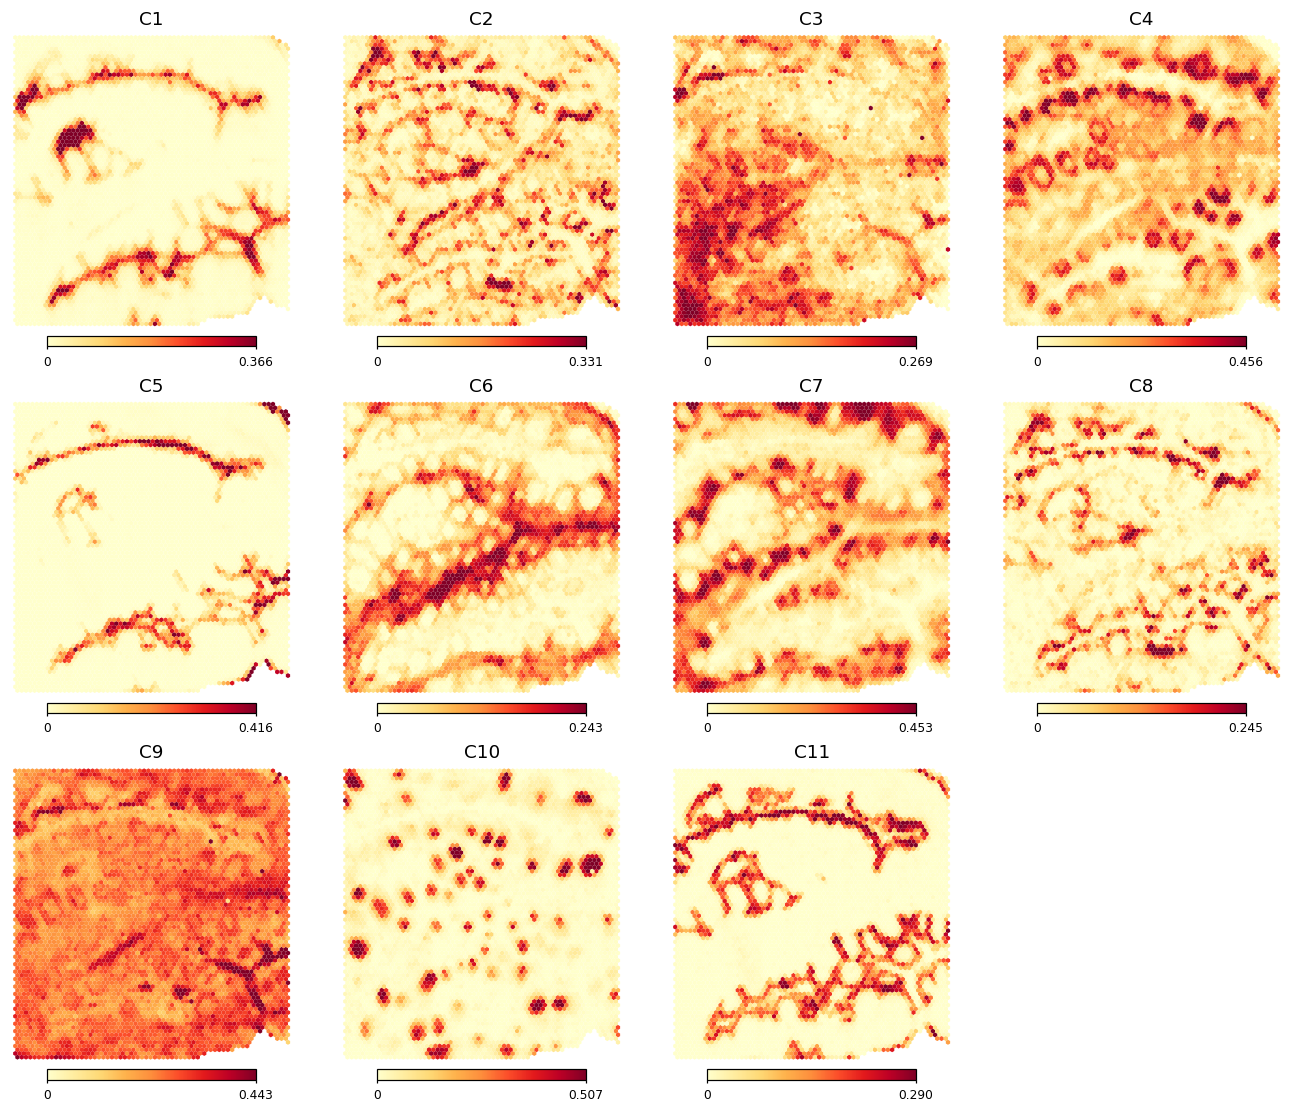

In [4]:
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

array_row, array_col = data["coordinates"].T
plot_xy = np.column_stack((array_col / 2, array_row * np.sqrt(3) / 2))
angles = np.deg2rad(np.arange(30, 390, 60))
offsets = np.column_stack((np.cos(angles), np.sin(angles))) / np.sqrt(3)
vertices = plot_xy[:, None, :] + offsets
limits = np.quantile(p, .99, axis=0)
save_table(pd.DataFrame({"component": [f"C{k+1}" for k in range(p.shape[1])],
                         "display_min": 0., "display_max_q99": limits,
                         "full_weight_max": p.max(axis=0),
                         "n_above_display_max": (p > limits).sum(axis=0),
                         "n_spots": len(p)}), "tonsil_joint_display_scales")

fig, axes = plt.subplots(3, 4, figsize=(12, 10), layout="constrained")
for k, ax in enumerate(axes.ravel()):
    if k == p.shape[1]:
        ax.axis("off")
        continue
    art = PolyCollection(vertices, array=p[:, k], cmap="YlOrRd",
                         norm=Normalize(0, limits[k]), edgecolors="none",
                         linewidths=0, rasterized=True)
    ax.add_collection(art)
    ax.set(xlim=(plot_xy[:, 0].min()-1, plot_xy[:, 0].max()+1),
           ylim=(plot_xy[:, 1].max()+1, plot_xy[:, 1].min()-1),
           aspect="equal", title=f"C{k+1}")
    ax.axis("off")
    bar = fig.colorbar(art, ax=ax, orientation="horizontal", shrink=.65,
                       pad=.025, fraction=.045, ticks=[0, limits[k]])
    bar.ax.set_xticklabels(["0", f"{limits[k]:.3f}"])
    bar.ax.tick_params(labelsize=8, length=2)
save_figure(fig, "tonsil_joint_structure")


## 5. Export the joint weights

The table below reports each joint component's mean contribution across all spots. Exported values retain their original scale, including values above the plotting limits. Molecular contributions are not cell-count fractions. Inspect component profiles and independent annotations before assigning biological names.

In [5]:
components = [f"C{k+1}" for k in range(p.shape[1])]
display(save_table(pd.DataFrame({"component": components,
                                 "mean_weight": p.mean(axis=0)}),
                   "tonsil_joint_summary"))
out = ROOT / "outputs/tonsil"
out.mkdir(parents=True, exist_ok=True)
pd.DataFrame(p, index=data["spots"], columns=components).to_csv(out / "joint_weights.csv")


,component,mean_weight
0,C1,0.039443
1,C2,0.080041
2,C3,0.097198
3,C4,0.149611
4,C5,0.032400
5,C6,0.064595
6,C7,0.140725
7,C8,0.040730
8,C9,0.248762
9,C10,0.058976


## 6. Adapt the analysis

Use the same spot ordering and matched-feature names for your own paired assays. To run an assay-only control, pass a one-entry dictionary with `eta=0` and no links; the manuscript controls allow up to 80,000 iterations. For a reference-based paired model, pass one harmonized reference per assay, with identical reference-type order, and use `eta=0` because fixed profiles have no learned modality deviations.